In [1]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, mean_absolute_percentage_error
from tensorflow import keras
import numpy as np
import pandas as pd
from pandas import DataFrame
import matplotlib.pyplot as plt

def clarke_error_grid(ref_values,
                      pred_values,
                      title_string,
                      show_plot=False,
                      minimum_sensor_reading=40,
                      maximum_sensor_reading=500):
    """
      This function takes in the reference values and the prediction values as lists and returns a list with each index corresponding to the total number
     of points within that zone (0=A, 1=B, 2=C, 3=D, 4=E) and the plot
    """
    # Checking to see if the lengths of the reference and prediction arrays are the same
    assert (len(ref_values) == len(
        pred_values)), "Unequal number of values (reference : {0}) (prediction : {1}).".format(len(ref_values),
                                                                                               len(pred_values))

    # Checks to see if the values are within the normal sensor measurement range, otherwise it gives a warning
    # Reference values
    if min(ref_values) < minimum_sensor_reading:
        print(
            f'Input Warning: the minimum reference value ({min(ref_values):.2f}) is below the limit of sensor design (Inferior limit: {minimum_sensor_reading} mg/dL).')
        number_ref_values_low_limit = sum(value < minimum_sensor_reading for value in ref_values)
        print(f"Number of reference values below the limit: {number_ref_values_low_limit}")
        print()

    if max(ref_values) > maximum_sensor_reading:
        print(
            f'Input Warning: the maximum reference value ({max(ref_values):.2f}) is above the limit of sensor design (Superior limit: {maximum_sensor_reading} mg/dL).')
        number_ref_values_up_limit = sum(value > maximum_sensor_reading for value in ref_values)
        print(f"Number of reference values above the limit: {number_ref_values_up_limit}")
        print()

    # Predicted values
    min_ref_value = min(pred_values)
    min_ref_value = round(min_ref_value, 2)
    number_pred_values_low_limit = 0
    if min_ref_value < minimum_sensor_reading:
        print(
            f'Input Warning: the minimum predicted value ({min_ref_value:.2f}) is below the minimum input value (Inferior limit: {minimum_sensor_reading} mg/dL).')
        number_pred_values_low_limit = sum(value < minimum_sensor_reading for value in pred_values)
        # list_of_values_low_limit = [value for value in pred_values if value < minimum_sensor_reading]
        print(f"Number of predicted values below the limit: {number_pred_values_low_limit}")
        print()

    max_ref_value = max(pred_values)
    max_ref_value = round(max_ref_value, 2)
    number_pred_values_up_limit = 0
    if max_ref_value > maximum_sensor_reading:
        print(
            f'Input Warning: the maximum predicted value ({max_ref_value:.2f}) is above the maximum input value (Superior limit: {maximum_sensor_reading} mg/dL).')
        number_pred_values_up_limit = sum(value > maximum_sensor_reading for value in pred_values)
        # list_of_values_up_limit = [value for value in pred_values if value > maximum_sensor_reading]
        print(f"Number of predicted values above the limit: {number_pred_values_up_limit}")
        print()

    # list of out of range values
    out_range_values = [min_ref_value, number_pred_values_low_limit, max_ref_value, number_pred_values_up_limit]

    if show_plot:
        # Clear plot
        plt.clf()

        # Clasificar puntos por rango
        bar_colors = ['indianred', 'red', 'limegreen', 'yellow',
                      'orange']  # ['TBR-L2', 'TBR-L1', 'TIR', 'TAR-L1', 'TAR-L2']

        color_by_range = []
        for val in ref_values:
            if val < 54:
                color_by_range.append(bar_colors[0])
            elif val < 70:
                color_by_range.append(bar_colors[1])
            elif val <= 180:
                color_by_range.append(bar_colors[2])
            elif val <= 250:
                color_by_range.append(bar_colors[3])
            else:
                color_by_range.append(bar_colors[4])

        # Scatter plot con colores por rango
        plt.scatter(ref_values, pred_values, marker='o', c=color_by_range, s=1)

        # plt.title(title_string + " Clarke Error Grid")
        plt.xlabel("Reference Concentration (mg/dl)")
        plt.ylabel("Prediction Concentration (mg/dl)")
        plt.xticks([0, 50, 100, 150, 200, 250, 300, 350, 400, 450, 500])
        plt.yticks([0, 50, 100, 150, 200, 250, 300, 350, 400, 450, 500])
        plt.gca().set_facecolor('white')

        # Set axes lengths
        plt.gca().set_xlim([0, 500])
        plt.gca().set_ylim([0, 500])
        plt.gca().set_aspect((500) / (500))

        # Plot zone lines
        plt.plot([0, 500], [0, 500], ':', c='black', linewidth=1)  # Theoretical 45 regression line
        plt.plot([0, 175 / 3], [70, 70], '-', c='black', linewidth=1)
        # plt.plot([175/3, 320], [70, 500], '-', c='black', linewidth=1)
        plt.plot([175 / 3, 500 / 1.2], [70, 500], '-',
                 c='black',
                 linewidth=1)  # Replace 320 with 400/1.2 because 100*(400 - 400/1.2)/(400/1.2) =  20% error
        plt.plot([70, 70], [84, 500], '-', c='black', linewidth=1)
        plt.plot([0, 70], [180, 180], '-', c='black', linewidth=1)
        plt.plot([70, 290], [180, 500], '-', c='black', linewidth=1)
        # plt.plot([70, 70], [0, 175/3], '-', c='black', linewidth=1)
        plt.plot([70, 70], [0, 56], '-', c='black',
                 linewidth=1)  # Replace 175.3 with 56 because 100*abs(56-70)/70) = 20% error
        # plt.plot([70, 500],[175/3, 320],'-', c='black', linewidth=1)

        plt.plot([70, 500], [56, 400.79], '-', c='black', linewidth=1)  ##########################

        plt.plot([180, 180], [0, 70], '-', c='black', linewidth=1)
        plt.plot([180, 500], [70, 70], '-', c='black', linewidth=1)
        plt.plot([240, 240], [70, 180], '-', c='black', linewidth=1)
        plt.plot([240, 500], [180, 180], '-', c='black', linewidth=1)
        plt.plot([130, 180], [0, 70], '-', c='black', linewidth=1)

        # Add zone titles

        plt.text(30, 15, "A", fontsize=15, fontweight='bold')
        plt.text(400, 250, "B", fontsize=15, fontweight='bold')
        plt.text(270, 400, "B", fontsize=15, fontweight='bold')
        plt.text(150, 400, "C", fontsize=15, fontweight='bold')
        plt.text(155, 15, "C", fontsize=15, fontweight='bold')
        plt.text(30, 120, "D", fontsize=15, fontweight='bold')
        plt.text(370, 120, "D", fontsize=15, fontweight='bold')
        plt.text(30, 340, "E", fontsize=15, fontweight='bold')
        plt.text(370, 15, "E", fontsize=15, fontweight='bold')

        plt.savefig(f'plots/Clarke_Error_Grid{title_string}.png', dpi=350, bbox_inches='tight')

    # Statistics from the data
    zone = [0] * 5
    for i in range(len(ref_values)):
        if (ref_values[i] <= 70 and pred_values[i] <= 70) or (
                pred_values[i] <= 1.2 * ref_values[i] and pred_values[i] >= 0.8 * ref_values[i]):
            zone[0] += 1  # Zone A

        elif (ref_values[i] >= 180 and pred_values[i] <= 70) or (ref_values[i] <= 70 and pred_values[i] >= 180):
            zone[4] += 1  # Zone E

        elif ((ref_values[i] >= 70 and ref_values[i] <= 290) and pred_values[i] >= ref_values[i] + 110) or (
                (ref_values[i] >= 130 and ref_values[i] <= 180) and (
                pred_values[i] <= (7 / 5) * ref_values[i] - 182)):
            zone[2] += 1  # Zone C
        elif (ref_values[i] >= 240 and (pred_values[i] >= 70 and pred_values[i] <= 180)) or (
                ref_values[i] <= 175 / 3 and pred_values[i] <= 180 and pred_values[i] >= 70) or (
                (ref_values[i] >= 175 / 3 and ref_values[i] <= 70) and pred_values[i] >= (6 / 5) * ref_values[i]):
            zone[3] += 1  # Zone D
        else:
            zone[1] += 1  # Zone B

    return zone, out_range_values


# def get_values_per_zone(values):
#     keys = ['A', 'B', 'C', 'D', 'E']
#     return {key: value for key, value in zip(keys, values)}

def test_by_range(df_result_vector: pd.DataFrame,
                  grid_name: str,
                  minimum_sensor_reading=40,
                  maximum_sensor_reading=500) -> tuple[DataFrame, DataFrame, DataFrame]:
    df_result_vector_TBR_2 = df_result_vector[df_result_vector['y_test'] < 54]

    df_result_vector_TBR_1 = df_result_vector[
        (df_result_vector['y_test'] >= 54) & (df_result_vector['y_test'] < 70)]

    df_result_vector_TIR = df_result_vector[(df_result_vector['y_test'] >= 70) & (df_result_vector['y_test'] < 181)]

    df_result_vector_TAR_1 = df_result_vector[
        (df_result_vector['y_test'] >= 181) & (df_result_vector['y_test'] < 251)]

    df_result_vector_TAR_2 = df_result_vector[(df_result_vector['y_test'] >= 251)]

    list_dataframe_by_range = [df_result_vector,
                               df_result_vector_TBR_2, df_result_vector_TBR_1,
                               df_result_vector_TIR,
                               df_result_vector_TAR_1, df_result_vector_TAR_2]
    list_dataframe_by_range_name = ['ENTIRE', 'TBR_2', 'TBR_1', 'TIR', 'TAR_1', 'TAR_2']

    df_metrics_summary = pd.DataFrame(columns=['Range', 'A', 'B', 'C', 'D', 'E', 'A + B', 'RMSE', 'MSE', 'MAE', 'MAPE'])
    df_zones_values = pd.DataFrame(columns=['Range', 'A', 'B', 'C', 'D', 'E'])
    df_limits = pd.DataFrame(
        columns=['Range', 'Minimum value', 'Number values below limit', 'Maximum value', 'Number values above limit'])

    for i in range(6):
        reference_values = list_dataframe_by_range[i]['y_test']
        pred_values = list_dataframe_by_range[i]['y_predict']
        print(f'------- Zone: {list_dataframe_by_range_name[i]} -------')
        if list_dataframe_by_range_name[i] == 'ENTIRE':  # Plot the graph for the ENTIRE zone
            zone, out_of_range_values = clarke_error_grid(ref_values=reference_values.values,
                                                          pred_values=pred_values.values,
                                                          title_string=grid_name,
                                                          show_plot=True,
                                                          minimum_sensor_reading=minimum_sensor_reading,
                                                          maximum_sensor_reading=maximum_sensor_reading)
        else:  # Do not plot the graph for the other zones
            zone, out_of_range_values = clarke_error_grid(ref_values=reference_values.values,
                                                          pred_values=pred_values.values,
                                                          title_string=grid_name + list_dataframe_by_range_name[i],
                                                          show_plot=False,
                                                          minimum_sensor_reading=minimum_sensor_reading,
                                                          maximum_sensor_reading=maximum_sensor_reading)

        # Clinical metrics
        print(f'Zones: [A, B, C, D, E]')
        print(f'Number of points by zone: {zone}')
        zone_percentages = round(pd.Series(zone) / reference_values.shape[0] * 100, 2)

        new_row_zone_values = {'Range': list_dataframe_by_range_name[i],
                               'A': zone[0],
                               'B': zone[1],
                               'C': zone[2],
                               'D': zone[3],
                               'E': zone[4]}
        new_index_zone_values = len(df_zones_values)
        df_zones_values.loc[new_index_zone_values] = new_row_zone_values

        print(f'Percentage of point by zone: {zone_percentages.tolist()}')
        print()

        # Non-clinical metrics
        mse = mean_squared_error(reference_values, pred_values)
        rmse = np.sqrt(mean_squared_error(reference_values, pred_values))
        mae = mean_absolute_error(reference_values, pred_values)
        mape = mean_absolute_percentage_error(reference_values, pred_values)

        print(f'Mean Squared Error (MSE): {mse:.2f}')
        print(f'Root Mean Squared Error (RMSE): {rmse:.2f}')
        print(f'Mean absolute Error (MAE): {mae:.2f}')
        print(f'Mean absolute percentage Error (MAPE): {mape:.2f}')

        new_row_metrics = {'Range': list_dataframe_by_range_name[i],
                           'A': zone_percentages[0],
                           'B': zone_percentages[1],
                           'C': zone_percentages[2],
                           'D': zone_percentages[3],
                           'E': zone_percentages[4],
                           'A + B': zone_percentages[0] + zone_percentages[1],
                           'RMSE': rmse,
                           'MSE': mse,
                           'MAE': mae,
                           'MAPE': mape}
        new_index_metrics = len(df_metrics_summary)
        df_metrics_summary.loc[new_index_metrics] = new_row_metrics

        # Save the limits of the values
        new_row_limits = {'Range': list_dataframe_by_range_name[i],
                          'Minimum value': out_of_range_values[0],
                          'Number values below limit': out_of_range_values[1],
                          'Maximum value': out_of_range_values[2],
                          'Number values above limit': out_of_range_values[3]}
        new_index_limits = len(df_limits)
        df_limits.loc[new_index_limits] = new_row_limits

        print()
        print('-' * 100)
        print()

    return df_metrics_summary, df_zones_values, df_limits

def get_train_plots_loss(hist: keras.callbacks, name: str):
    fig, ax = plt.subplots()

    # data
    x_epoch = hist.epoch
    y_val_loss = hist.history['val_loss']
    y_train_loss = hist.history['loss']

    # Create a line plots
    ax.plot(x_epoch, y_val_loss, label='Validation loss', color='orange', linestyle='-')
    ax.plot(x_epoch, y_train_loss, label='Train loss', color='blue', linestyle='-')

    # Add labels and title
    ax.set_xlabel('Epoch')
    ax.set_ylabel('Loss')
    ax.set_title('Training and validation loss')

    ax.legend()

    fig.savefig(name + '_Loss.pdf', dpi=350, bbox_inches='tight')

def get_train_plots_RMSE(hist: keras.callbacks, name: str):
    fig, ax = plt.subplots()

    # Sample data
    x_epoch = hist.epoch
    y_val_rmse = hist.history['val_root_mean_squared_error']
    y_train_rmse = hist.history['root_mean_squared_error']

    # Create a line plot
    ax.plot(x_epoch, y_val_rmse, label='Validation RMSE', color='orange', linestyle='-')
    ax.plot(x_epoch, y_train_rmse, label='Train RMSE', color='blue', linestyle='-')

    # Add labels and title
    ax.set_xlabel('Epoch')
    ax.set_ylabel('RMSE')
    ax.set_title('Training and validation RMSE')

    # Add a legend
    ax.legend()

    # Display the plot
    fig.savefig(name + '_RMSE.pdf', dpi=350, bbox_inches='tight')

def get_train_plots_MSE(hist: keras.callbacks, name: str):
    fig, ax = plt.subplots()

    # Sample data
    x_epoch = hist.epoch
    y_val_mse = hist.history['val_mean_squared_error']
    y_train_mse = hist.history['mean_squared_error']

    # Create a line plot
    ax.plot(x_epoch, y_val_mse, label='Validation MSE', color='orange', linestyle='-')
    ax.plot(x_epoch, y_train_mse, label='Train MSE', color='blue', linestyle='-')

    # Add labels and title
    ax.set_xlabel('Epoch')
    ax.set_ylabel('MSE')
    ax.set_title('Training and validation MSE')

    # Add a legend
    ax.legend()

    # Display the plot
    fig.savefig(name + '_MSE.pdf', dpi=350, bbox_inches='tight')


In [2]:
# path_predictions = 'c:/Users/Ciro/Mi Unidad (PDI)/_UGR_PDI_2024-05-30/RELIEF-T1D/Python_projects/Glucose_prediction_2025/Custom_loss_functions/Exp1/test_results/df_test_results_vectors_CNN_H2_EloyPenaltyp01_Fold1.parquet'
path_predictions = 'test_results/df_test_results_vectors_LSTM_H2.parquet'

df_test_results = pd.read_parquet(path_predictions)

current_algorithm = 'CNN_500'  # Change this to the algorithm you are using
current_horizon = 2  # Change this to the horizon you are using
minimum_sensor_reading = 38  # Minimum sensor reading limit
maximum_sensor_reading = 401  # Maximum sensor reading limit

In [3]:
df_test_results

,y_test,y_predict
0,215.00000,206.874374
1,212.00000,202.474548
2,195.00000,205.060257
3,189.00000,203.002106
4,185.00000,177.869598
...,...,...
2261437,105.90822,118.940010
2261438,102.91086,104.815292
2261439,113.90130,108.643906
2261440,140.87790,106.519852


------- Zone: ENTIRE -------
Input Warning: the minimum reference value (38.00) is below the limit of sensor design (Inferior limit: 38.96 mg/dL).
Number of reference values below the limit: 26
Zones: [A, B, C, D, E]
Number of points by zone: [1834968, 380369, 2162, 43829, 114]
Percentage of point by zone: [81.14, 16.82, 0.1, 1.94, 0.01]

Mean Squared Error (MSE): 1029.35
Root Mean Squared Error (RMSE): 32.08
Mean absolute Error (MAE): 21.43
Mean absolute percentage Error (MAPE): 0.12

----------------------------------------------------------------------------------------------------

------- Zone: TBR_2 -------
Input Warning: the minimum reference value (38.00) is below the limit of sensor design (Inferior limit: 38.96 mg/dL).
Number of reference values below the limit: 26

Zones: [A, B, C, D, E]
Number of points by zone: [1962, 0, 0, 7658, 24]
Percentage of point by zone: [20.34, 0.0, 0.0, 79.41, 0.25]

Mean Squared Error (MSE): 1719.19
Root Mean Squared Error (RMSE): 41.46
Mean abs

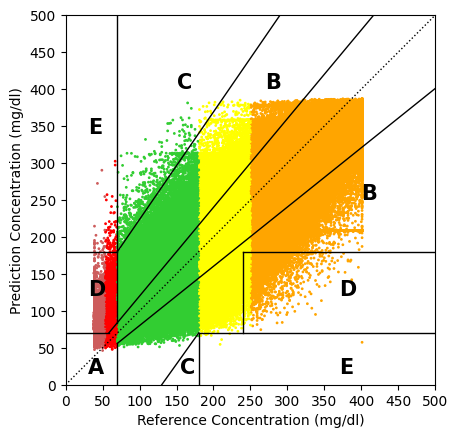

In [5]:

df_metrics_by_range, df_zone_values, df_limits = test_by_range(df_test_results,
                                                                           f'_{current_algorithm}_H{current_horizon}',
                                                                           minimum_sensor_reading,
                                                                           maximum_sensor_reading)
df_metrics_by_range = df_metrics_by_range.round(2)

In [ ]:

df_metrics_by_range.to_csv(f'test_results/metrics_performance_by_range_{current_algorithm}_H{current_horizon}.csv',
                       index=False)

df_zone_values.to_csv(f'test_results/number_of points_by_zones_{current_algorithm}_H{current_horizon}.csv',
                  index=False)

df_limits.to_csv(f'test_results/predictions_out_of_limits_{current_algorithm}_H{current_horizon}.csv',
             index=False)